# Saldo migratorio por cada 1.000 habitantes

In [ ]:
# Parámetros de la gráfica
SLUG = "seguridad-social"  # carpeta en research/temas/
GRAFICA_ID = "saldo-migratorio"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Saldo migratorio por cada 1.000 habitantes"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "por cada 1.000 habitantes"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = 0  # línea horizontal en el 0: separa la llegada neta (encima) de la salida neta (debajo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** La diferencia entre las personas que llegan a vivir al país y las que se van en un año, por cada 1.000 habitantes: el *saldo migratorio*. Cuenta a todas las personas que cambian de país de residencia, con independencia de su nacionalidad (también los españoles que emigran o vuelven) y de su situación administrativa.

**Cómo se lee.** Un valor de 10 significa que ese año llegaron 10 personas más de las que se fueron por cada 1.000 habitantes. Un valor negativo indica que se fueron más de las que llegaron, como en España en los años posteriores a la crisis de 2008. La línea en el 0 separa los dos casos.

**Limitaciones.**
- **Eurostat lo calcula por diferencia:** la variación de la población en el año menos el crecimiento natural (nacimientos menos defunciones). Por eso incluye las correcciones estadísticas de las cifras de población, como las depuraciones del padrón, y no solo los movimientos registrados.
- **EE. UU., Canadá y OCDE** salen del Banco Mundial, que publica las estimaciones de Naciones Unidas (*World Population Prospects*). Para los últimos años son estimaciones y proyecciones que se revisan en cada edición y pueden alejarse mucho de las cifras nacionales: la sección 3 lo comprueba con España.

## 2. Descarga

- **España y UE-27:** Eurostat, indicadores demográficos (`demo_gind`), tasa bruta de saldo migratorio con el ajuste estadístico (`CNMIGRATRT`), por 1.000 habitantes.
- **OCDE, EE. UU. y Canadá:** Banco Mundial, saldo migratorio neto (`SM.POP.NETM`, personas) y población total (`SP.POP.TOTL`, a mitad de año). La media de la OCDE es el agregado `OED` (miembros de la OCDE). También España, para compararla con Eurostat.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat, worldbank
from lib.tipos import FuenteMeta

eu, fuentes_eu = eurostat.get("demo_gind", {"freq": "A", "indic_de": "CNMIGRATRT"}, desde=DESDE)
PAISES_BM = {"OED": "ocde", "USA": "eeuu", "CAN": "canada", "ESP": "espana_bm"}
neto, fuentes_neto = worldbank.get("SM.POP.NETM", paises=PAISES_BM, desde=DESDE)
pob, _ = worldbank.get("SP.POP.TOTL", paises=PAISES_BM, desde=DESDE)

## 3. Transformación

- **España y UE-27:** Eurostat, sin transformar.
- **OCDE, EE. UU. y Canadá:** saldo migratorio neto entre la población, por 1.000.
- Comprobación: el mismo cálculo para España frente a la tasa de Eurostat.

In [ ]:
tasa = (
    neto.pivot(index="periodo", columns="serie", values="valor")
    / pob.pivot(index="periodo", columns="serie", values="valor") * 1000
)
bm = tasa.stack().rename("valor").reset_index().rename(columns={"level_1": "serie"})[["serie", "periodo", "valor"]]
df = pd.concat([eu, bm[bm["serie"].isin(["ocde", "eeuu", "canada"])]], ignore_index=True)
assert df["valor"].between(-60, 60).all(), "tasa fuera de rango: ¿unidades?"

HOY = fuentes_eu[0].fecha_consulta
fuentes = [
    FuenteMeta(f.serie, f.organismo, "demo_gind (indic_de=CNMIGRATRT)", f.url, f.fecha_consulta) for f in fuentes_eu
] + [
    FuenteMeta(s, worldbank.ORGANISMO, "SM.POP.NETM / SP.POP.TOTL × 1000",
               worldbank.URL_INDICADOR.format(indicador="SM.POP.NETM"), HOY)
    for s in ("ocde", "eeuu", "canada")
]

serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
comp = pd.DataFrame({"Eurostat": serie(eu, "espana"), "Banco Mundial": tasa["espana_bm"]}).dropna()
comp["BM − Eurostat"] = comp["Banco Mundial"] - comp["Eurostat"]
display(comp.round(1).loc[2015:])
dif = comp["BM − Eurostat"]
HASTA = 2020
DIF_HASTA = dif.loc[:HASTA].abs().max()
ANIO_MAX = int(dif.abs().idxmax())
ULT = int(comp.index.max())

,Eurostat,Banco Mundial,BM − Eurostat
periodo,,,
2015,-0.1,-0.0,0.1
2016,1.7,2.3,0.6
2017,3.8,4.3,0.5
2018,7.0,7.2,0.2
2019,9.7,9.9,0.2
2020,5.0,5.0,0.0
2021,4.2,3.0,-1.2
2022,15.3,6.3,-9.0
2023,13.4,2.5,-10.9


### Notas

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


NOTAS = [
    "España y UE-27: Eurostat, tasa bruta de saldo migratorio con el ajuste estadístico (demo_gind, CNMIGRATRT), por "
    "1.000 habitantes. Eurostat la calcula como la variación de la población menos el crecimiento natural, por lo que "
    "incluye las correcciones de las cifras de población (en España, del padrón). Media UE-27 de composición actual "
    "(EU27_2020).",
    "OCDE, EE. UU. y Canadá: Banco Mundial, saldo migratorio neto (SM.POP.NETM) entre la población total "
    "(SP.POP.TOTL), por 1.000; son estimaciones de Naciones Unidas (World Population Prospects). La media de la OCDE "
    "es el agregado de los países miembros (OED) del Banco Mundial.",
    f"España en las dos fuentes: hasta {HASTA}, la tasa calculada con el Banco Mundial difiere de la de Eurostat como "
    f"mucho {fmt(DIF_HASTA)} puntos, pero en los últimos años se separa: en {ANIO_MAX}, {fmt(comp.loc[ANIO_MAX, 'Banco Mundial'])} "
    f"por 1.000 frente a {fmt(comp.loc[ANIO_MAX, 'Eurostat'])}, y en {ULT}, {fmt(comp.loc[ULT, 'Banco Mundial'])} frente a "
    f"{fmt(comp.loc[ULT, 'Eurostat'])}. Las cifras de Naciones Unidas de los últimos años son estimaciones y "
    f"proyecciones que se revisan en cada edición, así que las de EE. UU., Canadá y la OCDE pueden cambiar mucho.",
    "Cuenta a todas las personas que cambian de país de residencia, con independencia de su nacionalidad y de su "
    "situación administrativa.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, tasa bruta de saldo migratorio con el ajuste estadístico (demo_gind, CNMIGRATRT), por 1.000 habitantes. Eurostat la calcula como la variación de la población menos el crecimiento natural, por lo que incluye las correcciones de las cifras de población (en España, del padrón). Media UE-27 de composición actual (EU27_2020).
- OCDE, EE. UU. y Canadá: Banco Mundial, saldo migratorio neto (SM.POP.NETM) entre la población total (SP.POP.TOTL), por 1.000; son estimaciones de Naciones Unidas (World Population Prospects). La media de la OCDE es el agregado de los países miembros (OED) del Banco Mundial.
- España en las dos fuentes: hasta 2020, la tasa calculada con el Banco Mundial difiere de la de Eurostat como mucho 3,5 puntos, pero en los últimos años se separa: en 2023, 2,5 por 1.000 frente a 13,4, y en 2025, 2,0 frente a 11,8. Las cifras de Naciones Unidas de los últimos años son estimaciones y proyecciones que se revisan en cada edición, así que las de EE. UU., C

## 4. Visualización

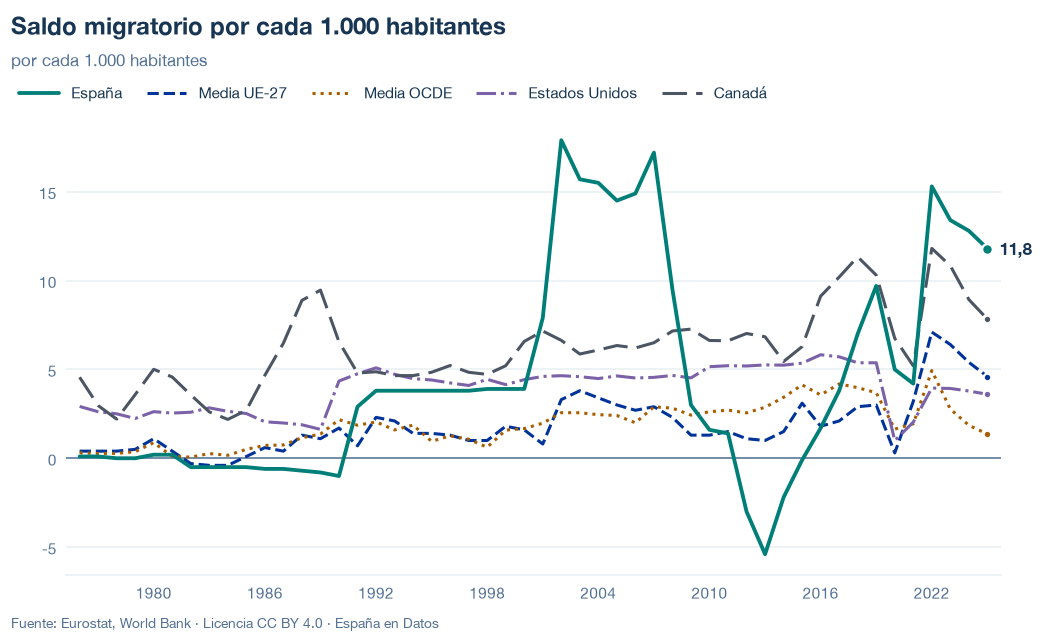

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/saldo-migratorio.json y data/saldo-migratorio.csv


## 6. Fuentes, notas y licencia

- Eurostat, `demo_gind` (`CNMIGRATRT`): España y UE-27.
- Banco Mundial, `SM.POP.NETM` y `SP.POP.TOTL`: OCDE (`OED`), EE. UU., Canadá y, para comparar, España.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.